# 03 — Model Building & Evaluation

**Phase 5** (see `CONTINUITY.md`). The training code lives in `src/train.py` (run `python -m src.train`, ~3 min). This notebook presents its results and checks that the saved model reloads and predicts.

Setup used for every model: `Pipeline(preprocessor → model)` with `class_weight='balanced'` (Phase 4 decision), 5-fold stratified CV on the **training set only**; the test set is touched exactly once, at the end.

In [1]:
import json, sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_prep import clean, split
from src.load_data import load_raw

def show(png, width=11):
    img = plt.imread(ROOT / "reports" / "figures" / png)
    h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(width, width * h / w)); ax.imshow(img); ax.axis("off"); plt.show()

metrics = json.loads((ROOT / "reports" / "model_metrics.json").read_text())

## Feature reduction: 19 → 9 inputs
`src/select_features.py` ranked the 19 input fields by out-of-fold permutation importance (training set only) and re-ran 5-fold CV keeping the top *k*. Accuracy is flat down to 9 inputs, then falls. The model below uses those 9 (`src/features.py`).

 k  roc_auc  roc_auc_std  recall     f1
19   0.8486       0.0097  0.7920 0.6311
18   0.8486       0.0100  0.7940 0.6318
17   0.8490       0.0105  0.7940 0.6357
16   0.8495       0.0103  0.7953 0.6344
15   0.8494       0.0100  0.7913 0.6324
14   0.8489       0.0104  0.7913 0.6346
13   0.8485       0.0104  0.7933 0.6345
12   0.8493       0.0108  0.7906 0.6330
11   0.8489       0.0096  0.7926 0.6363
10   0.8484       0.0111  0.7913 0.6339
 9   0.8475       0.0108  0.7920 0.6322
 8   0.8458       0.0109  0.7880 0.6324
 7   0.8431       0.0106  0.7900 0.6313
 6   0.8400       0.0092  0.7960 0.6273
 5   0.8392       0.0120  0.7880 0.6285
 4   0.8373       0.0137  0.7933 0.6227
 3   0.8336       0.0122  0.7993 0.6241

Kept (9):     ['Contract', 'InternetService', 'tenure', 'TotalCharges', 'OnlineSecurity', 'TechSupport', 'PaymentMethod', 'MonthlyCharges', 'MultipleLines']
Dropped (10): ['PaperlessBilling', 'OnlineBackup', 'StreamingMovies', 'StreamingTV', 'gender', 'SeniorCitizen', 'PhoneServ

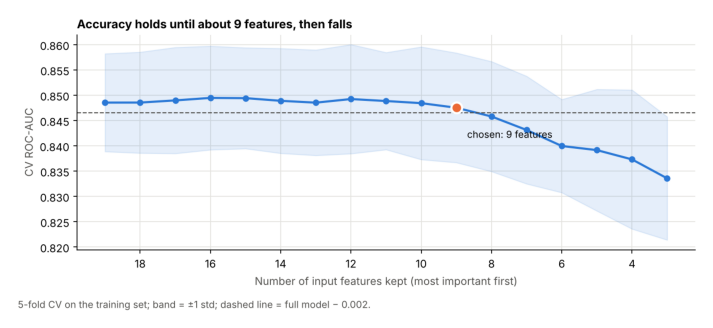

In [2]:
sel = pd.read_csv(ROOT / "reports" / "feature_selection.csv")
print(sel[["k", "roc_auc", "roc_auc_std", "recall", "f1"]].round(4).to_string(index=False))
from src.features import SELECTED_FEATURES, DROPPED_FEATURES
print()
print("Kept (9):    ", SELECTED_FEATURES)
print("Dropped (10):", DROPPED_FEATURES)
show("15_feature_selection.png", 9)

**Before vs after on the held-out test set:** 19 inputs → ROC-AUC 0.845, 299 churners caught, 280 false alarms. 9 inputs → ROC-AUC 0.845, 300 caught, 271 false alarms. Same accuracy, less than half the data to collect.

## 5.1–5.3 Baseline + four models, 5-fold cross-validation
XGBoost and LightGBM are added automatically by `src/train.py` when installed (`pip install xgboost lightgbm`).

               model  recall  precision    f1  roc_auc  roc_auc_std
 Logistic Regression   0.797      0.511 0.623    0.844        0.014
       Random Forest   0.765      0.539 0.632    0.841        0.012
HistGradientBoosting   0.744      0.535 0.622    0.837        0.011
       Decision Tree   0.789      0.496 0.609    0.825        0.010


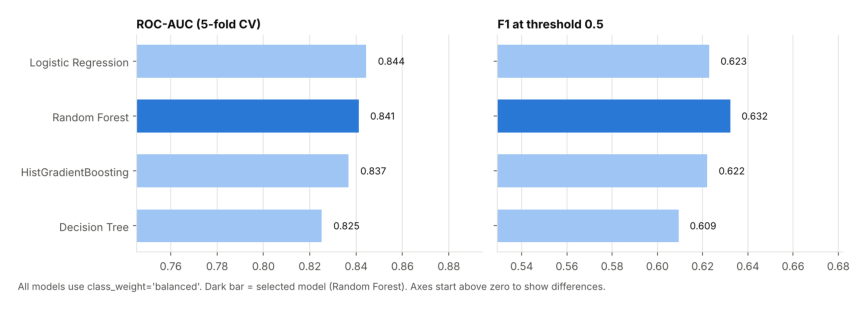

In [3]:
comp = pd.read_csv(ROOT / "reports" / "model_comparison.csv")
print(comp[["model", "recall", "precision", "f1", "roc_auc", "roc_auc_std"]].round(3).to_string(index=False))
show("08_model_comparison.png")

Logistic Regression (the baseline) and Random Forest are effectively tied on ROC-AUC (~0.84); the single Decision Tree is clearly weakest. Differences between the top models are within one standard deviation across folds — this dataset's signal is largely captured by a linear model.

## 5.5 Tuning the top two + the decision threshold

In [4]:
tuned = pd.read_csv(ROOT / "reports" / "tuning_results.csv")
print(tuned.round(4).to_string(index=False))
print(f"\nSelected: {metrics['selected_model']}")
print(f"Engineered features re-check (Phase 4 follow-up): CV ROC-AUC {metrics['engineered_features_cv_roc_auc']} "
      f"vs {tuned.cv_roc_auc_tuned.max():.4f} without -> no meaningful gain, not used")
print(f"\nThreshold rule: highest threshold whose out-of-fold recall >= {metrics['target_recall']:.0%}")
print(f"Chosen threshold: {metrics['threshold']}  |  out-of-fold: {metrics['out_of_fold']}")

              model  cv_roc_auc_tuned                                                                            best_params
      Random Forest            0.8475 {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 16, 'n_estimators': 306}
Logistic Regression            0.8444                                                                         {'C': 0.98467}

Selected: Random Forest
Engineered features re-check (Phase 4 follow-up): CV ROC-AUC 0.8474 vs 0.8475 without -> no meaningful gain, not used

Threshold rule: highest threshold whose out-of-fold recall >= 80%
Chosen threshold: 0.4929  |  out-of-fold: {'oof_recall': 0.8, 'oof_precision': 0.5223, 'oof_f1': 0.632, 'oof_roc_auc': 0.8464}


## 5.4 Final evaluation on the held-out test set (1,409 customers)

             threshold  recall  precision     f1  accuracy   tn   fp  fn   tp
chosen           0.493   0.802      0.525  0.635     0.755  764  271  74  300
default 0.5      0.500   0.794      0.524  0.631     0.754  765  270  77  297

Test ROC-AUC: 0.845


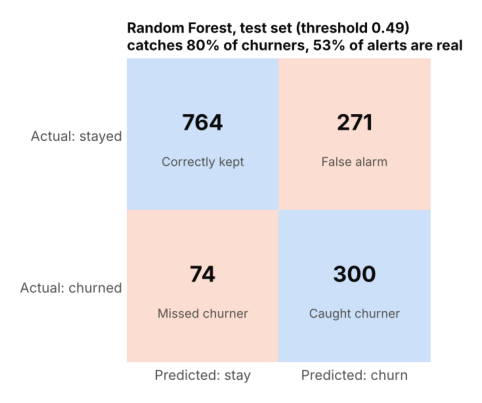

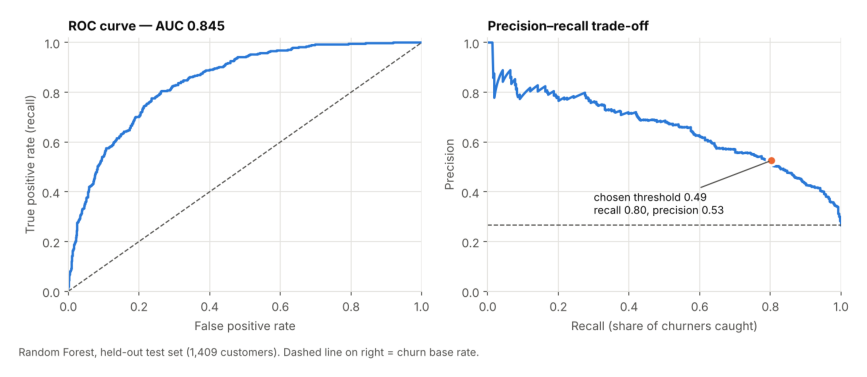

In [5]:
t = metrics["test"]
rows = []
for label in ("tuned_threshold", "default_0.5"):
    m = t[label]
    rows.append({"threshold": m["threshold"], "recall": m["recall"], "precision": m["precision"],
                 "f1": m["f1"], "accuracy": m["accuracy"], **m["confusion"]})
print(pd.DataFrame(rows, index=["chosen", "default 0.5"]).round(3).to_string())
print(f"\nTest ROC-AUC: {t['roc_auc']:.3f}")
show("09_confusion_matrix.png", width=6)
show("10_roc_pr_curves.png")

**Reading the result:** out of 374 customers who actually churned in the test set, the model flags **300 (80%)**. About half of all flagged customers really churn (precision 0.53) — roughly 2× better than contacting customers at random (base rate 26.5%). Test-set numbers match the cross-validation estimates closely, so the model is not overfitting.

The threshold is a business choice: raising it sends fewer false alarms but misses more churners. The precision–recall curve above shows the full trade-off.

## 5.6 Saved model reloads and predicts

In [6]:
bundle = joblib.load(ROOT / "models" / "churn_model.pkl")
pipe, threshold = bundle["pipeline"], bundle["threshold"]
print("Loaded:", bundle["model_name"], "| trained", bundle["trained_on"], "| threshold", round(threshold, 3))

_, X_test, _, y_test = split(clean(load_raw()))
sample = X_test.head(5)
proba = pipe.predict_proba(sample)[:, 1]
out = sample[["tenure", "Contract", "InternetService", "PaymentMethod", "MonthlyCharges"]].copy()
out["churn_probability"] = proba.round(3)
out["flag"] = ["AT RISK" if p >= threshold else "ok" for p in proba]
out["actual"] = y_test.head(5).map({1: "churned", 0: "stayed"}).values
print(out.to_string())

Loaded: Random Forest | trained 2026-11-05 | threshold 0.493
      tenure        Contract InternetService            PaymentMethod  MonthlyCharges  churn_probability     flag  actual
437       72        Two year     Fiber optic  Credit card (automatic)          114.05              0.064       ok  stayed
2280       8  Month-to-month     Fiber optic  Credit card (automatic)          100.15              0.807  AT RISK  stayed
2235      41        One year             DSL  Credit card (automatic)           78.35              0.216       ok  stayed
4460      18  Month-to-month     Fiber optic         Electronic check           78.20              0.678  AT RISK  stayed
3761      72        Two year             DSL  Credit card (automatic)           82.65              0.051       ok  stayed
